<a href="https://colab.research.google.com/github/Oluwadara17/COHORT-RENTION-ANALYSIS/blob/main/prediction_of_frankrupt_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import libracies
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix


The dataset called "diabetes" which pima variable was assign to is the PIMA, while the dataset called "Frankrupt diabetes" which data variable was assign to is the FRANKFURT HOSPITAL, GERMANY.

In [ ]:
# Loading of the dataset
data = pd.read_csv("/content/drive/MyDrive/Frankrupt diabetes.csv")
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,138,62,35,0,33.6,0.127,47,1
1,0,84,82,31,125,38.2,0.233,23,0
2,0,145,0,0,0,44.2,0.630,31,1
3,0,135,68,42,250,42.3,0.365,24,1
4,1,139,62,41,480,40.7,0.536,21,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               2000 non-null   int64  
 1   Glucose                   2000 non-null   int64  
 2   BloodPressure             2000 non-null   int64  
 3   SkinThickness             2000 non-null   int64  
 4   Insulin                   2000 non-null   int64  
 5   BMI                       2000 non-null   float64
 6   DiabetesPedigreeFunction  2000 non-null   float64
 7   Age                       2000 non-null   int64  
 8   Outcome                   2000 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 140.8 KB


In [ ]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.703500,121.182500,69.145500,20.935000,80.254000,32.193000,0.470930,33.090500,0.342000
std,3.306063,32.068636,19.188315,16.103243,111.180534,8.149901,0.323553,11.786423,0.474498
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,63.500000,0.000000,0.000000,27.375000,0.244000,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,40.000000,32.300000,0.376000,29.000000,0.000000
75%,6.000000,141.000000,80.000000,32.000000,130.000000,36.800000,0.624000,40.000000,1.000000
max,17.000000,199.000000,122.000000,110.000000,744.000000,80.600000,2.420000,81.000000,1.000000


In [ ]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [ ]:
data['Outcome'].value_counts()

0    1316
1     684
Name: Outcome, dtype: int64

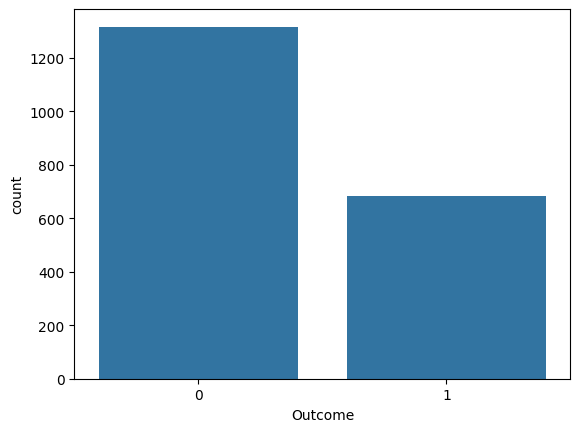

In [ ]:
sns.countplot(data=data, x=data['Outcome'])
plt.show()

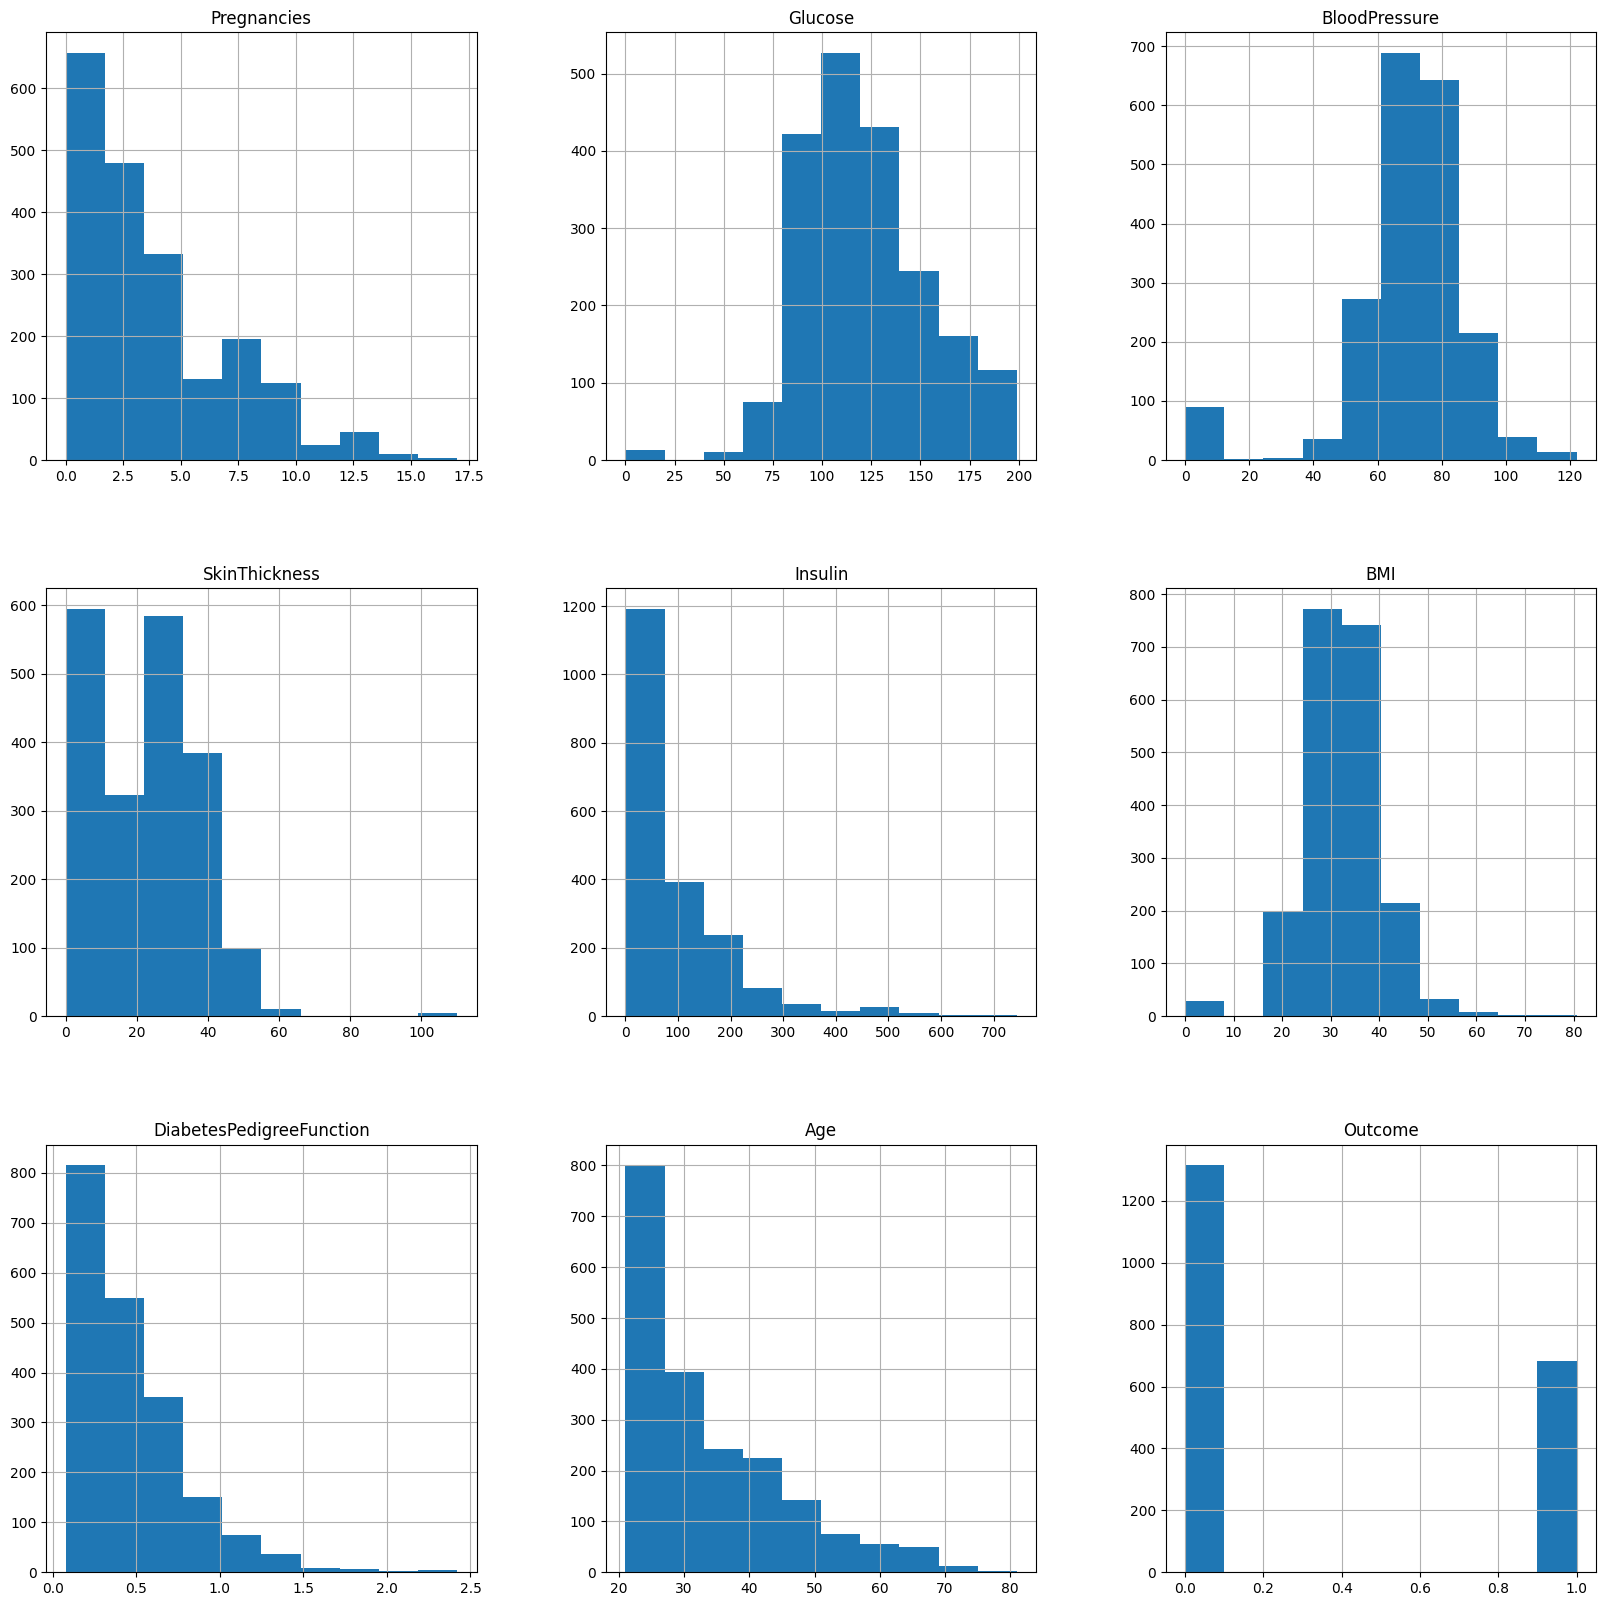

In [ ]:
p = data.hist(figsize = (20,20))

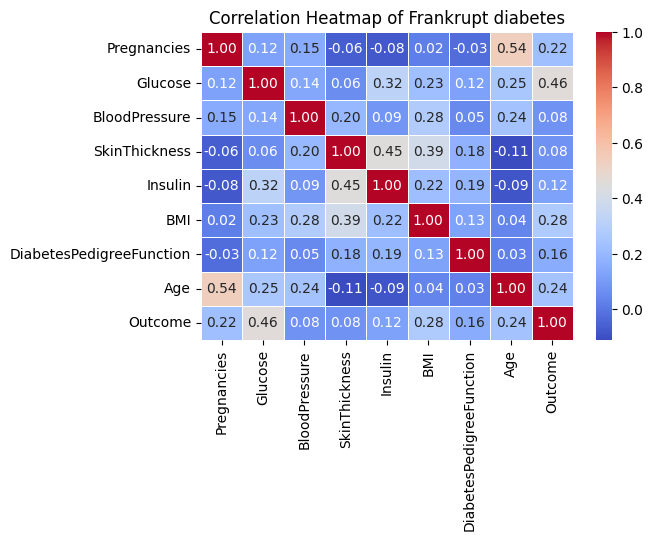

In [ ]:
# Calculating correlation matrix
correlation_matrix = data.corr()

# Plotting correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Frankrupt diabetes')
plt.show()

In [ ]:
# scaling
sc_X = StandardScaler()
X =  pd.DataFrame(sc_X.fit_transform(data.drop(["Outcome"],axis = 1),),
        columns=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'])
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.515394,0.524553,-0.372481,0.873645,-0.722016,0.172683,-1.063246,1.180424
1,-1.120495,-1.159756,0.670080,0.625186,0.402563,0.737249,-0.735551,-0.856326
2,-1.120495,0.742890,-3.604422,-1.300374,-0.722016,1.473638,0.491759,-0.177409
3,-1.120495,0.430980,-0.059713,1.308449,1.527142,1.240448,-0.327478,-0.771462
4,-0.817945,0.555744,-0.372481,1.246334,3.596367,1.044077,0.201161,-1.026055


In [ ]:
y=data.Outcome

In [ ]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
rf_model = RandomForestClassifier().fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.9666666666666667

In [ ]:
# classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.97      0.97       389
           1       0.94      0.96      0.95       211

    accuracy                           0.97       600
   macro avg       0.96      0.97      0.96       600
weighted avg       0.97      0.97      0.97       600



In [ ]:
# parameter grid for Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the Random Forest classifier
rf = RandomForestClassifier()

# Initialize GridSearchCV with the Random Forest classifier and parameter grid
grid_search_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search_rf.fit(X_train, y_train)

# best parameters found by GridSearchCV for Random Forest
best_params_rf = grid_search_rf.best_params_
print("Best Parameters for Random Forest:", best_params_rf)

# best cross-validation score found by GridSearchCV for Random Forest
best_score_rf = grid_search_rf.best_score_
print("Best Cross-Validation Score for Random Forest:", best_score_rf)

# best Random Forest model found by GridSearchCV
best_rf = grid_search_rf.best_estimator_

# predictions on the test data using the best Random Forest model
y_pred_rf = best_rf.predict(X_test)

# classification report for Random Forest
report_rf = classification_report(y_test, y_pred_rf)
print("Classification Report for Random Forest:")
print(report_rf)

Best Parameters for Random Forest: {'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-Validation Score for Random Forest: 0.9335714285714287
Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       389
           1       0.93      0.97      0.95       211

    accuracy                           0.96       600
   macro avg       0.96      0.97      0.96       600
weighted avg       0.97      0.96      0.97       600



In [ ]:
# Create an SVM classifier with a linear kernel
clf2= SVC(kernel='linear')
clf2.fit(X_train,y_train)
pred2 =clf2.predict(X_test)
accuracy_score(y_test,pred2)

# classification report
print(classification_report(y_test, pred2))

              precision    recall  f1-score   support

           0       0.82      0.90      0.85       389
           1       0.77      0.63      0.69       211

    accuracy                           0.80       600
   macro avg       0.79      0.76      0.77       600
weighted avg       0.80      0.80      0.80       600



In [ ]:
# Define a parameter grid for SVM
param_grid_svm = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [1, 0.1, 0.01, 0.001],  # Kernel coefficient
    'kernel': ['rbf', 'linear']  # Kernel type
}

# Initialize the SVM classifier
svm = SVC()

# Initialize GridSearchCV with the SVM classifier and parameter grid
grid_search_svm = GridSearchCV(svm, param_grid_svm, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search_svm.fit(X_train, y_train)

# best parameters found by GridSearchCV for SVM
best_params_svm = grid_search_svm.best_params_
print("Best Parameters for SVM:", best_params_svm)

# best cross-validation score found by GridSearchCV for SVM
best_score_svm = grid_search_svm.best_score_
print("Best Cross-Validation Score for SVM:", best_score_svm)

# best SVM model found by GridSearchCV
best_svm = grid_search_svm.best_estimator_

# predictions on the test data using the best SVM model
y_pred_svm = best_svm.predict(X_test)

# classification report for SVM
report_svm = classification_report(y_test, y_pred_svm)
print("Classification Report for SVM:")
print(report_svm)


Best Parameters for SVM: {'C': 10, 'gamma': 1, 'kernel': 'rbf'}
Best Cross-Validation Score for SVM: 0.925
Classification Report for SVM:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       389
           1       0.91      0.89      0.90       211

    accuracy                           0.93       600
   macro avg       0.92      0.92      0.92       600
weighted avg       0.93      0.93      0.93       600



In [ ]:
# Initialize the KNN classifier with n_neighbors=2
knn = KNeighborsClassifier(n_neighbors=2)

# Fit the KNN classifier on the training data
knn.fit(X_train, y_train)

# Make predictions on the test data
y_pred = knn.predict(X_test)

# Generate a classification report
report = classification_report(y_test, y_pred)

# Print the classification report
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       389
           1       0.91      0.71      0.80       211

    accuracy                           0.87       600
   macro avg       0.88      0.84      0.85       600
weighted avg       0.88      0.87      0.87       600



In [ ]:
# Define a parameter grid
param_grid = {
    'n_neighbors': range(1, 50),
    'weights': ['uniform', 'distance'],  # Weighting of neighbors
    'metric': ['euclidean', 'manhattan']  # Distance metric
}

# Initialize the KNN classifier
knn = KNeighborsClassifier()

# Initialize GridSearchCV with the KNN classifier and parameter grid
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# best parameters found by GridSearchCV
best_params = grid_search.best_params_
print("Best Parameters:", best_params)

# best cross-validation score found by GridSearchCV
best_score = grid_search.best_score_
print("Best Cross-Validation Score:", best_score)

# best KNN model found by GridSearchCV
best_knn = grid_search.best_estimator_

# predictions on the test data using the best KNN model
y_pred = best_knn.predict(X_test)

# Print the classification report
report = classification_report(y_test, y_pred)
print("Classification Report:")
print(report)


Best Parameters: {'metric': 'manhattan', 'n_neighbors': 45, 'weights': 'distance'}
Best Cross-Validation Score: 0.9335714285714285
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       389
           1       0.98      0.94      0.96       211

    accuracy                           0.97       600
   macro avg       0.98      0.97      0.97       600
weighted avg       0.97      0.97      0.97       600

